<a href="https://colab.research.google.com/github/Sukhi-r/Brain_tumor_3D_Unet/blob/main/Train_100_20_30.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi

Fri Oct 23 20:29:48 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   32C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No CUDA GPU detected.")

PyTorch version: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4


In [3]:
!pip -q install "monai[nibabel]" nibabel matplotlib pandas

In [4]:
import os
import glob
import random
import numpy as np
import pandas as pd
import nibabel as nib
import matplotlib.pyplot as plt
import torch
import monai

print("MONAI version:", monai.__version__)
print("Device:", "cuda" if torch.cuda.is_available() else "cpu")

MONAI version: 1.6.1
Device: cuda


In [5]:
import os

root_dir = "/content/data"
data_dir = f"{root_dir}/Task01_BrainTumour"

os.makedirs(root_dir, exist_ok=True)

print("Root folder created:", os.path.exists(root_dir))
print("Dataset already available:", os.path.exists(data_dir))

Root folder created: True
Dataset already available: False


In [6]:
from monai.apps import DecathlonDataset

dataset = DecathlonDataset(
    root_dir=root_dir,
    task="Task01_BrainTumour",
    section="training",
    download=True,
    cache_rate=0.0,
    num_workers=2,
)

print("Dataset download and extraction completed.")

Task01_BrainTumour.tar: 7.09GB [05:00, 25.3MB/s]                            


2026-10-23 20:38:00,431 - INFO - Verified 'Task01_BrainTumour.tar', md5: 240a19d752f0d9e9101544901065d872.
2026-10-23 20:38:00,433 - INFO - Downloaded: /content/data/Task01_BrainTumour.tar
2026-10-23 20:38:00,434 - INFO - Writing into directory: /content/data.
Dataset download and extraction completed.


In [7]:
import glob

image_files = sorted(glob.glob(f"{data_dir}/imagesTr/*.nii.gz"))
label_files = sorted(glob.glob(f"{data_dir}/labelsTr/*.nii.gz"))

print("Training MRI files:", len(image_files))
print("Training label files:", len(label_files))

Training MRI files: 484
Training label files: 484


In [8]:
import os
import glob
import random
import json

images_dir = f"{data_dir}/imagesTr"
labels_dir = f"{data_dir}/labelsTr"

image_files = sorted(glob.glob(f"{images_dir}/*.nii.gz"))

all_cases = []

for image_path in image_files:
    patient_id = os.path.basename(image_path).replace(".nii.gz", "")
    label_path = f"{labels_dir}/{patient_id}.nii.gz"

    if os.path.exists(label_path):
        all_cases.append({
            "image": image_path,
            "label": label_path,
            "patient_id": patient_id,
        })

print("Total matched MRI-label patient cases:", len(all_cases))

random_seed = 42
random.Random(random_seed).shuffle(all_cases)

train_files = all_cases[:100]
val_files = all_cases[100:120]
test_files = all_cases[120:150]

print("\nDataset split")
print("Training cases:", len(train_files))
print("Validation cases:", len(val_files))
print("Test cases:", len(test_files))

print("\nFirst five training patients:")
print([case["patient_id"] for case in train_files[:5]])

print("\nFirst five validation patients:")
print([case["patient_id"] for case in val_files[:5]])

print("\nFirst five test patients:")
print([case["patient_id"] for case in test_files[:5]])

Total matched MRI-label patient cases: 484

Dataset split
Training cases: 100
Validation cases: 20
Test cases: 30

First five training patients:
['BRATS_370', 'BRATS_157', 'BRATS_042', 'BRATS_046', 'BRATS_229']

First five validation patients:
['BRATS_386', 'BRATS_311', 'BRATS_473', 'BRATS_469', 'BRATS_039']

First five test patients:
['BRATS_210', 'BRATS_069', 'BRATS_295', 'BRATS_383', 'BRATS_073']


In [9]:
split_info = {
    "random_seed": random_seed,
    "training_patients": [case["patient_id"] for case in train_files],
    "validation_patients": [case["patient_id"] for case in val_files],
    "test_patients": [case["patient_id"] for case in test_files],
}

os.makedirs("/content/outputs", exist_ok=True)

split_path = "/content/outputs/patient_split_100_20_30.json"

with open(split_path, "w") as file:
    json.dump(split_info, file, indent=2)

print("Saved reproducible split to:", split_path)

Saved reproducible split to: /content/outputs/patient_split_100_20_30.json


In [10]:
def convert_brats_labels(label):
    """
    Converts MSD Task01 label map into 3 binary segmentation channels.

    Input label values:
        0 = background
        1 = necrotic / non-enhancing tumor
        2 = edema
        3 = enhancing tumor

    Output channels:
        Channel 0 = Whole Tumor (WT): labels 1, 2, 3
        Channel 1 = Tumor Core (TC): labels 1, 3
        Channel 2 = Enhancing Tumor (ET): label 3
    """
    whole_tumor = label > 0
    tumor_core = np.logical_or(label == 1, label == 3)
    enhancing_tumor = label == 3

    return np.stack(
        [whole_tumor, tumor_core, enhancing_tumor],
        axis=0
    ).astype(np.float32)

In [11]:
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Lambdad,
    CropForegroundd,
    SpatialPadd,
    RandCropByPosNegLabeld,
    RandFlipd,
    RandRotate90d,
    RandScaleIntensityd,
    RandShiftIntensityd,
    NormalizeIntensityd,
    EnsureTyped,
)

patch_size = (64, 64, 64)

train_transforms = Compose([
    LoadImaged(keys=["image", "label"]),

    # MRI input: (H, W, D, 4) → (4, H, W, D)
    EnsureChannelFirstd(keys="image", channel_dim=-1),

    # Label map: (H, W, D) → (3, H, W, D): WT, TC, ET
    Lambdad(keys="label", func=convert_brats_labels),

    # Remove outer black region around brain
    CropForegroundd(keys=["image", "label"], source_key="image"),

    # Guarantee valid patch dimensions
    SpatialPadd(keys=["image", "label"], spatial_size=patch_size),

    # 75% tumor-positive sampling, 25% background sampling
    RandCropByPosNegLabeld(
        keys=["image", "label"],
        label_key="label",
        spatial_size=patch_size,
        pos=3,
        neg=1,
        num_samples=4,
        image_key="image",
        image_threshold=0,
    ),

    # Normalize every MRI modality independently
    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True,
    ),

    # Spatial augmentation
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=0),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=1),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=2),
    RandRotate90d(keys=["image", "label"], prob=0.5, max_k=3),

    # Mild MRI intensity augmentation
    RandScaleIntensityd(keys="image", factors=0.10, prob=0.30),
    RandShiftIntensityd(keys="image", offsets=0.10, prob=0.30),

    EnsureTyped(keys=["image", "label"]),
])

val_transforms = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys="image", channel_dim=-1),
    Lambdad(keys="label", func=convert_brats_labels),
    CropForegroundd(keys=["image", "label"], source_key="image"),
    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True,
    ),
    EnsureTyped(keys=["image", "label"]),
])

In [12]:
sample_patches = train_transforms(train_files[0])

print("Type returned:", type(sample_patches))
print("Patches produced from one MRI:", len(sample_patches))

first_patch = sample_patches[0]

print("\nMRI patch shape:", first_patch["image"].shape)
print("Segmentation patch shape:", first_patch["label"].shape)
print("MRI datatype:", first_patch["image"].dtype)
print("Label datatype:", first_patch["label"].dtype)

print("\nMRI minimum and maximum:")
print(
    float(first_patch["image"].min()),
    float(first_patch["image"].max())
)

print("\nTumor voxels in patch by output region:")
print(
    "WT:", int(first_patch["label"][0].sum()),
    "| TC:", int(first_patch["label"][1].sum()),
    "| ET:", int(first_patch["label"][2].sum())
)

Type returned: <class 'list'>
Patches produced from one MRI: 4

MRI patch shape: torch.Size([4, 64, 64, 64])
Segmentation patch shape: torch.Size([3, 64, 64, 64])
MRI datatype: torch.float32
Label datatype: torch.float32

MRI minimum and maximum:
-3.8861231803894043 10.572049140930176

Tumor voxels in patch by output region:
WT: 38789 | TC: 31716 | ET: 8583


In [13]:
from monai.data import Dataset, DataLoader

train_ds = Dataset(
    data=train_files,
    transform=train_transforms,
)

val_ds = Dataset(
    data=val_files,
    transform=val_transforms,
)

train_loader = DataLoader(
    train_ds,
    batch_size=1,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

val_loader = DataLoader(
    val_ds,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print("Training MRI cases:", len(train_ds))
print("Validation MRI cases:", len(val_ds))
print("Training iterations per epoch:", len(train_loader))
print("Validation iterations:", len(val_loader))

Training MRI cases: 100
Validation MRI cases: 20
Training iterations per epoch: 100
Validation iterations: 20


In [14]:
from monai.networks.nets import UNet
from monai.losses import DiceLoss

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=3,
    channels=(8, 16, 32, 64, 128),
    strides=(2, 2, 2, 2),
    num_res_units=2,
    norm="INSTANCE",
).to(device)

dice_loss_function = DiceLoss(
    sigmoid=True,
    squared_pred=True,
)

bce_loss_function = torch.nn.BCEWithLogitsLoss()

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-5,
)

print("Device:", device)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}"
)

Device: cuda
Trainable parameters: 1,204,658


In [15]:
batch = next(iter(train_loader))

images = batch["image"].to(device)
labels = batch["label"].to(device)

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

with torch.no_grad():
    logits = model(images)

print("Model output shape:", logits.shape)

assert images.shape[1] == 4, "Expected four MRI input modalities."
assert labels.shape[1] == 3, "Expected WT, TC, and ET label channels."
assert logits.shape[1] == 3, "Expected three model output channels."

with torch.no_grad():
    dice_loss_value = dice_loss_function(logits, labels)
    bce_loss_value = bce_loss_function(logits, labels)
    combined_loss_value = dice_loss_value + 0.5 * bce_loss_value

print(f"\nDice loss: {dice_loss_value.item():.4f}")
print(f"BCE loss: {bce_loss_value.item():.4f}")
print(f"Combined loss: {combined_loss_value.item():.4f}")

print("\n✅ DataLoader, compact 3D U-Net, and loss functions work correctly.")

Image batch shape: torch.Size([4, 4, 64, 64, 64])
Label batch shape: torch.Size([4, 3, 64, 64, 64])
Model output shape: torch.Size([4, 3, 64, 64, 64])

Dice loss: 0.7714
BCE loss: 0.8342
Combined loss: 1.1885

✅ DataLoader, compact 3D U-Net, and loss functions work correctly.


In [16]:
from monai.data import Dataset, DataLoader
from monai.inferers import sliding_window_inference

val_monitor_files = val_files[:5]

val_monitor_ds = Dataset(
    data=val_monitor_files,
    transform=val_transforms,
)

val_monitor_loader = DataLoader(
    val_monitor_ds,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print("Validation-monitor patients:", len(val_monitor_ds))
print("Patient IDs:")
print([case["patient_id"] for case in val_monitor_files])

Validation-monitor patients: 5
Patient IDs:
['BRATS_386', 'BRATS_311', 'BRATS_473', 'BRATS_469', 'BRATS_039']


In [17]:
def evaluate_full_volumes(model, data_loader, device, roi_size=(64, 64, 64)):
    """
    Evaluates a model on complete 3D MRI volumes using sliding-window inference.
    Returns mean WT, TC, ET, and mean Dice scores.
    """
    model.eval()

    all_dice_scores = []

    with torch.no_grad():
        for batch_data in data_loader:
            images = batch_data["image"].to(device)
            targets = batch_data["label"].to(device)

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):
                logits = sliding_window_inference(
                    inputs=images,
                    roi_size=roi_size,
                    sw_batch_size=2,
                    predictor=model,
                    overlap=0.25,
                )

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities > 0.5).float()

            intersection = (
                predictions * targets
            ).sum(dim=(2, 3, 4))

            denominator = (
                predictions.sum(dim=(2, 3, 4))
                + targets.sum(dim=(2, 3, 4))
            )

            dice_per_region = (
                (2.0 * intersection + 1e-6)
                / (denominator + 1e-6)
            )

            all_dice_scores.append(
                dice_per_region.squeeze(0).cpu().numpy()
            )

    all_dice_scores = np.array(all_dice_scores)

    return {
        "WT Dice": float(np.mean(all_dice_scores[:, 0])),
        "TC Dice": float(np.mean(all_dice_scores[:, 1])),
        "ET Dice": float(np.mean(all_dice_scores[:, 2])),
        "Mean Dice": float(np.mean(all_dice_scores)),
    }

In [ ]:
import time
import os
import json

max_epochs = 20
validation_interval = 2
early_stopping_patience = 5

best_val_wt_dice = -1.0
no_improvement_checks = 0

model_dir = "/content/models"
os.makedirs(model_dir, exist_ok=True)

best_model_path = f"{model_dir}/best_3d_unet_100train.pth"

history = {
    "epoch": [],
    "train_loss": [],
    "validation_wt_dice": [],
    "validation_tc_dice": [],
    "validation_et_dice": [],
    "validation_mean_dice": [],
}

scaler = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

print("Starting training...")
print("Training patients:", len(train_files))
print("Patches per patient:", 4)
print("Approximate patches per epoch:", len(train_files) * 4)
print("Validation monitor patients:", len(val_monitor_files))
print("Maximum epochs:", max_epochs)

for epoch in range(1, max_epochs + 1):
    epoch_start_time = time.time()

    model.train()
    epoch_loss = 0.0

    for step, batch_data in enumerate(train_loader, start=1):
        inputs = batch_data["image"].to(device)
        targets = batch_data["label"].to(device)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):
            logits = model(inputs)

            dice_loss = dice_loss_function(logits, targets)
            bce_loss = bce_loss_function(logits, targets)

            loss = dice_loss + 0.5 * bce_loss

        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()

        epoch_loss += loss.item()

        if step % 20 == 0 or step == len(train_loader):
            print(
                f"Epoch {epoch:02d}/{max_epochs} | "
                f"Step {step:03d}/{len(train_loader)} | "
                f"Loss: {loss.item():.4f}"
            )

    mean_train_loss = epoch_loss / len(train_loader)
    epoch_time = time.time() - epoch_start_time

    print(
        f"\nEpoch {epoch:02d} completed | "
        f"Mean training loss: {mean_train_loss:.4f} | "
        f"Training time: {epoch_time / 60:.1f} minutes"
    )

    # Run full-volume validation every two epochs
    if epoch % validation_interval == 0:
        print("\nRunning full-volume validation...")
        torch.cuda.empty_cache()

        validation_metrics = evaluate_full_volumes(
            model=model,
            data_loader=val_monitor_loader,
            device=device,
            roi_size=(64, 64, 64),
        )

        print(
            f"Validation results at epoch {epoch}"
            f"\nWT Dice:   {validation_metrics['WT Dice']:.4f}"
            f"\nTC Dice:   {validation_metrics['TC Dice']:.4f}"
            f"\nET Dice:   {validation_metrics['ET Dice']:.4f}"
            f"\nMean Dice: {validation_metrics['Mean Dice']:.4f}"
        )

        history["epoch"].append(epoch)
        history["train_loss"].append(mean_train_loss)
        history["validation_wt_dice"].append(
            validation_metrics["WT Dice"]
        )
        history["validation_tc_dice"].append(
            validation_metrics["TC Dice"]
        )
        history["validation_et_dice"].append(
            validation_metrics["ET Dice"]
        )
        history["validation_mean_dice"].append(
            validation_metrics["Mean Dice"]
        )

        # Save best checkpoint based on unseen validation WT Dice
        if validation_metrics["WT Dice"] > best_val_wt_dice:
            best_val_wt_dice = validation_metrics["WT Dice"]
            no_improvement_checks = 0

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "optimizer_state_dict": optimizer.state_dict(),
                    "best_validation_wt_dice": best_val_wt_dice,
                    "validation_metrics": validation_metrics,
                    "history": history,
                    "training_configuration": {
                        "training_patients": 100,
                        "validation_patients": 20,
                        "test_patients": 30,
                        "patch_size": [64, 64, 64],
                        "patches_per_patient": 4,
                        "loss": "DiceLoss + 0.5 * BCEWithLogitsLoss",
                        "learning_rate": 1e-4,
                    },
                },
                best_model_path,
            )

            print(
                f"\n✅ New best model saved."
                f"\nBest validation WT Dice: {best_val_wt_dice:.4f}"
                f"\nCheckpoint: {best_model_path}"
            )

        else:
            no_improvement_checks += 1

            print(
                f"\nNo validation WT Dice improvement."
                f"\nEarly-stopping counter: "
                f"{no_improvement_checks}/{early_stopping_patience}"
            )

            if no_improvement_checks >= early_stopping_patience:
                print("\nEarly stopping triggered.")
                break

    print("-" * 70)

history_df = pd.DataFrame(history)

history_path = "/content/outputs/training_history_100train.csv"
history_df.to_csv(history_path, index=False)

print("\nTraining finished.")
print(f"Best validation WT Dice: {best_val_wt_dice:.4f}")
print(f"Best-model checkpoint: {best_model_path}")
print(f"Training history CSV: {history_path}")

Starting training...
Training patients: 100
Patches per patient: 4
Approximate patches per epoch: 400
Validation monitor patients: 5
Maximum epochs: 20
Epoch 01/20 | Step 020/100 | Loss: 0.9274
Epoch 01/20 | Step 040/100 | Loss: 1.3437
Epoch 01/20 | Step 060/100 | Loss: 1.1344
Epoch 01/20 | Step 080/100 | Loss: 0.9754
Epoch 01/20 | Step 100/100 | Loss: 1.0844

Epoch 01 completed | Mean training loss: 1.1262 | Training time: 2.3 minutes
----------------------------------------------------------------------
Epoch 02/20 | Step 020/100 | Loss: 1.3182
Epoch 02/20 | Step 040/100 | Loss: 1.0096
Epoch 02/20 | Step 060/100 | Loss: 1.0086
Epoch 02/20 | Step 080/100 | Loss: 1.1985
Epoch 02/20 | Step 100/100 | Loss: 1.1748

Epoch 02 completed | Mean training loss: 1.0685 | Training time: 2.2 minutes

Running full-volume validation...
Validation results at epoch 2
WT Dice:   0.1047
TC Dice:   0.0933
ET Dice:   0.0047
Mean Dice: 0.0676

✅ New best model saved.
Best validation WT Dice: 0.1047
Checkpo

In [ ]:
from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Lambdad,
    CropForegroundd,
    SpatialPadd,
    RandCropByPosNegLabeld,
    RandFlipd,
    RandRotate90d,
    RandScaleIntensityd,
    RandShiftIntensityd,
    NormalizeIntensityd,
    EnsureTyped,
)

patch_size = (64, 64, 64)

train_transforms_v2 = Compose([
    LoadImaged(keys=["image", "label"]),

    # (H, W, D, 4) → (4, H, W, D)
    EnsureChannelFirstd(keys="image", channel_dim=-1),

    # (H, W, D) → (3, H, W, D): WT, TC, ET
    Lambdad(keys="label", func=convert_brats_labels),

    # Remove outer black area
    CropForegroundd(keys=["image", "label"], source_key="image"),

    # IMPORTANT: normalize complete cropped MRI volume before patch sampling
    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True,
    ),

    # Ensure volume is at least patch size
    SpatialPadd(keys=["image", "label"], spatial_size=patch_size),

    # Four patches per patient; tumor-positive patches sampled more frequently
    RandCropByPosNegLabeld(
        keys=["image", "label"],
        label_key="label",
        spatial_size=patch_size,
        pos=3,
        neg=1,
        num_samples=4,
        image_key="image",
        image_threshold=0,
    ),

    # Augmentation after consistent normalization
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=0),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=1),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=2),
    RandRotate90d(keys=["image", "label"], prob=0.5, max_k=3),

    RandScaleIntensityd(keys="image", factors=0.10, prob=0.30),
    RandShiftIntensityd(keys="image", offsets=0.10, prob=0.30),

    EnsureTyped(keys=["image", "label"]),
])

val_transforms_v2 = Compose([
    LoadImaged(keys=["image", "label"]),
    EnsureChannelFirstd(keys="image", channel_dim=-1),
    Lambdad(keys="label", func=convert_brats_labels),

    CropForegroundd(keys=["image", "label"], source_key="image"),

    # Same full-volume normalization rule as training
    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True,
    ),

    EnsureTyped(keys=["image", "label"]),
])

print("Corrected transforms created successfully.")

Corrected transforms created successfully.


In [ ]:
from monai.data import Dataset, DataLoader

train_ds_v2 = Dataset(
    data=train_files,
    transform=train_transforms_v2,
)

val_monitor_ds_v2 = Dataset(
    data=val_monitor_files,
    transform=val_transforms_v2,
)

train_loader_v2 = DataLoader(
    train_ds_v2,
    batch_size=1,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

val_monitor_loader_v2 = DataLoader(
    val_monitor_ds_v2,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

print("Training MRI cases:", len(train_ds_v2))
print("Validation-monitor cases:", len(val_monitor_ds_v2))
print("Training iterations per epoch:", len(train_loader_v2))

Training MRI cases: 100
Validation-monitor cases: 5
Training iterations per epoch: 100


In [ ]:
test_patches_v2 = train_transforms_v2(train_files[0])

print("Patches from one patient:", len(test_patches_v2))

test_patch_v2 = test_patches_v2[0]

print("Image shape:", test_patch_v2["image"].shape)
print("Label shape:", test_patch_v2["label"].shape)

print("\nImage mean per MRI channel:")
for channel in range(4):
    channel_mean = test_patch_v2["image"][channel].mean().item()
    channel_std = test_patch_v2["image"][channel].std().item()

    print(
        f"Channel {channel}: "
        f"mean = {channel_mean:.3f}, "
        f"std = {channel_std:.3f}"
    )


Patches from one patient: 4
Image shape: torch.Size([4, 64, 64, 64])
Label shape: torch.Size([3, 64, 64, 64])

Image mean per MRI channel:
Channel 0: mean = 0.388, std = 1.278
Channel 1: mean = 0.153, std = 0.726
Channel 2: mean = 0.170, std = 0.831
Channel 3: mean = 0.071, std = 0.886


In [ ]:
from monai.networks.nets import UNet
from monai.losses import DiceLoss

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_v2 = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=3,
    channels=(8, 16, 32, 64, 128),
    strides=(2, 2, 2, 2),
    num_res_units=2,
    norm="INSTANCE",
).to(device)

dice_loss_function_v2 = DiceLoss(
    sigmoid=True,
    squared_pred=True,
)

bce_loss_function_v2 = torch.nn.BCEWithLogitsLoss()

optimizer_v2 = torch.optim.AdamW(
    model_v2.parameters(),
    lr=1e-4,
    weight_decay=1e-5,
)

print("Fresh v2 model created on:", device)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in model_v2.parameters() if p.requires_grad):,}"
)

Fresh v2 model created on: cuda
Trainable parameters: 1,204,658


In [ ]:
from monai.networks.nets import UNet
from monai.losses import DiceLoss
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model_v2 = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=3,
    channels=(8, 16, 32, 64, 128),
    strides=(2, 2, 2, 2),
    num_res_units=2,
    norm="INSTANCE",
).to(device)

dice_loss_function_v2 = DiceLoss(
    sigmoid=True,
    squared_pred=True,
)

bce_loss_function_v2 = torch.nn.BCEWithLogitsLoss()

optimizer_v2 = torch.optim.AdamW(
    model_v2.parameters(),
    lr=1e-4,
    weight_decay=1e-5,
)

print("v2 model created on:", device)
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in model_v2.parameters() if p.requires_grad):,}"
)
print("Optimizer:", optimizer_v2)
print("✅ model_v2, loss functions, and optimizer_v2 are ready.")

v2 model created on: cuda
Trainable parameters: 1,204,658
Optimizer: AdamW (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: True
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.0001
    maximize: False
    weight_decay: 1e-05
)
✅ model_v2, loss functions, and optimizer_v2 are ready.


In [ ]:
print("train_loader_v2 exists:", "train_loader_v2" in globals())
print("val_monitor_loader_v2 exists:", "val_monitor_loader_v2" in globals())
print("model_v2 exists:", "model_v2" in globals())
print("optimizer_v2 exists:", "optimizer_v2" in globals())

train_loader_v2 exists: True
val_monitor_loader_v2 exists: True
model_v2 exists: True
optimizer_v2 exists: True


In [ ]:
import time
import os
import pandas as pd
import torch

max_epochs_v2 = 30
validation_interval_v2 = 3
early_stopping_patience_v2 = 4

best_val_wt_dice_v2 = -1.0
no_improvement_checks_v2 = 0

model_dir = "/content/models"
os.makedirs(model_dir, exist_ok=True)

best_model_path_v2 = f"{model_dir}/best_3d_unet_v2_100train.pth"

history_v2 = {
    "epoch": [],
    "train_loss": [],
    "validation_wt_dice": [],
    "validation_tc_dice": [],
    "validation_et_dice": [],
    "validation_mean_dice": [],
}

scaler_v2 = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

scheduler_v2 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_v2,
    T_max=max_epochs_v2,
    eta_min=1e-6,
)

print("Starting corrected v2 training...")
print("Training patients:", len(train_files))
print("Patches per patient:", 4)
print("Approximate training patches per epoch:", len(train_files) * 4)
print("Validation-monitor patients:", len(val_monitor_files))
print("Maximum epochs:", max_epochs_v2)
print("Validation interval:", validation_interval_v2, "epochs")
print("-" * 70)

for epoch in range(1, max_epochs_v2 + 1):
    epoch_start_time = time.time()

    model_v2.train()
    epoch_loss = 0.0

    for step, batch_data in enumerate(train_loader_v2, start=1):
        inputs = batch_data["image"].to(device)
        targets = batch_data["label"].to(device)

        optimizer_v2.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):
            logits = model_v2(inputs)

            dice_loss = dice_loss_function_v2(logits, targets)
            bce_loss = bce_loss_function_v2(logits, targets)

            loss = dice_loss + 0.5 * bce_loss

        scaler_v2.scale(loss).backward()
        scaler_v2.step(optimizer_v2)
        scaler_v2.update()

        epoch_loss += loss.item()

        if step % 20 == 0 or step == len(train_loader_v2):
            print(
                f"Epoch {epoch:02d}/{max_epochs_v2} | "
                f"Step {step:03d}/{len(train_loader_v2)} | "
                f"Loss: {loss.item():.4f}"
            )

    mean_train_loss = epoch_loss / len(train_loader_v2)
    scheduler_v2.step()

    current_lr = optimizer_v2.param_groups[0]["lr"]
    epoch_time_minutes = (time.time() - epoch_start_time) / 60

    print(
        f"\nEpoch {epoch:02d} completed"
        f"\nMean training loss: {mean_train_loss:.4f}"
        f"\nLearning rate: {current_lr:.7f}"
        f"\nTraining time: {epoch_time_minutes:.1f} minutes"
    )

    if epoch % validation_interval_v2 == 0:
        print("\nRunning full-volume validation on monitor patients...")
        torch.cuda.empty_cache()

        validation_metrics_v2 = evaluate_full_volumes(
            model=model_v2,
            data_loader=val_monitor_loader_v2,
            device=device,
            roi_size=(64, 64, 64),
        )

        print(
            f"\nValidation results at epoch {epoch}"
            f"\nWT Dice:   {validation_metrics_v2['WT Dice']:.4f}"
            f"\nTC Dice:   {validation_metrics_v2['TC Dice']:.4f}"
            f"\nET Dice:   {validation_metrics_v2['ET Dice']:.4f}"
            f"\nMean Dice: {validation_metrics_v2['Mean Dice']:.4f}"
        )

        history_v2["epoch"].append(epoch)
        history_v2["train_loss"].append(mean_train_loss)
        history_v2["validation_wt_dice"].append(
            validation_metrics_v2["WT Dice"]
        )
        history_v2["validation_tc_dice"].append(
            validation_metrics_v2["TC Dice"]
        )
        history_v2["validation_et_dice"].append(
            validation_metrics_v2["ET Dice"]
        )
        history_v2["validation_mean_dice"].append(
            validation_metrics_v2["Mean Dice"]
        )

        if validation_metrics_v2["WT Dice"] > best_val_wt_dice_v2:
            best_val_wt_dice_v2 = validation_metrics_v2["WT Dice"]
            no_improvement_checks_v2 = 0

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model_v2.state_dict(),
                    "optimizer_state_dict": optimizer_v2.state_dict(),
                    "best_validation_wt_dice": best_val_wt_dice_v2,
                    "validation_metrics": validation_metrics_v2,
                    "history": history_v2,
                    "training_configuration": {
                        "training_patients": 100,
                        "validation_patients": 20,
                        "test_patients": 30,
                        "patch_size": [64, 64, 64],
                        "patches_per_patient": 4,
                        "normalization": "full-volume normalization before patch sampling",
                        "loss": "DiceLoss + 0.5 * BCEWithLogitsLoss",
                        "optimizer": "AdamW",
                        "initial_learning_rate": 1e-4,
                        "scheduler": "CosineAnnealingLR",
                    },
                },
                best_model_path_v2,
            )

            print(
                f"\n✅ New best v2 model saved."
                f"\nBest validation WT Dice: {best_val_wt_dice_v2:.4f}"
                f"\nCheckpoint: {best_model_path_v2}"
            )

        else:
            no_improvement_checks_v2 += 1

            print(
                f"\nNo validation WT Dice improvement."
                f"\nEarly-stopping counter: "
                f"{no_improvement_checks_v2}/{early_stopping_patience_v2}"
            )

            if no_improvement_checks_v2 >= early_stopping_patience_v2:
                print("\nEarly stopping triggered.")
                break

    print("-" * 70) redew33

history_v2_df = pd.DataFrame(history_v2)

history_v2_path = "/content/outputs/training_history_v2_100train.csv"
history_v2_df.to_csv(history_v2_path, index=False)

print("\nCorrected v2 training finished.")
print(f"Best validation WT Dice: {best_val_wt_dice_v2:.4f}")
print(f"Best v2 model checkpoint: {best_model_path_v2}")
print(f"Training-history CSV: {history_v2_path}")

Starting corrected v2 training...
Training patients: 100
Patches per patient: 4
Approximate training patches per epoch: 400
Validation-monitor patients: 5
Maximum epochs: 30
Validation interval: 3 epochs
----------------------------------------------------------------------
Epoch 01/30 | Step 020/100 | Loss: 1.1713
Epoch 01/30 | Step 040/100 | Loss: 1.1423
Epoch 01/30 | Step 060/100 | Loss: 0.8398
Epoch 01/30 | Step 080/100 | Loss: 0.7502
Epoch 01/30 | Step 100/100 | Loss: 1.3072

Epoch 01 completed
Mean training loss: 1.0707
Learning rate: 0.0000997
Training time: 2.6 minutes
----------------------------------------------------------------------
Epoch 02/30 | Step 020/100 | Loss: 1.0680
Epoch 02/30 | Step 040/100 | Loss: 0.7633
Epoch 02/30 | Step 060/100 | Loss: 1.3328
Epoch 02/30 | Step 080/100 | Loss: 0.8543
Epoch 02/30 | Step 100/100 | Loss: 0.9297

Epoch 02 completed
Mean training loss: 0.9951
Learning rate: 0.0000989
Training time: 2.4 minutes
------------------------------------

In [19]:
import os
import glob
import random
import numpy as np
import pandas as pd
import torch

from monai.transforms import (
    Compose,
    LoadImaged,
    EnsureChannelFirstd,
    Lambdad,
    CropForegroundd,
    SpatialPadd,
    RandCropByPosNegLabeld,
    RandFlipd,
    RandRotate90d,
    RandScaleIntensityd,
    RandShiftIntensityd,
    NormalizeIntensityd,
    EnsureTyped,
)

from monai.data import Dataset, DataLoader
from monai.networks.nets import UNet
from monai.losses import DiceLoss
from monai.inferers import sliding_window_inference

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

root_dir = "/content/data"
data_dir = f"{root_dir}/Task01_BrainTumour"
images_dir = f"{data_dir}/imagesTr"
labels_dir = f"{data_dir}/labelsTr"

assert os.path.exists(images_dir), (
    "Dataset images folder not found. "
    "Run the dataset-download cell first."
)

assert os.path.exists(labels_dir), (
    "Dataset labels folder not found. "
    "Run the dataset-download cell first."
)

image_files = sorted(glob.glob(f"{images_dir}/*.nii.gz"))

all_cases = []

for image_path in image_files:
    patient_id = os.path.basename(image_path).replace(".nii.gz", "")
    label_path = f"{labels_dir}/{patient_id}.nii.gz"

    if os.path.exists(label_path):
        all_cases.append({
            "image": image_path,
            "label": label_path,
            "patient_id": patient_id,
        })

random_seed = 42
random.Random(random_seed).shuffle(all_cases)

train_files = all_cases[:100]
val_files = all_cases[100:120]
test_files = all_cases[120:150]

val_monitor_files = val_files[:5]

print("Total matched cases:", len(all_cases))
print("Training cases:", len(train_files))
print("Validation cases:", len(val_files))
print("Test cases:", len(test_files))
print("Validation-monitor cases:", len(val_monitor_files))

Device: cuda
Total matched cases: 484
Training cases: 100
Validation cases: 20
Test cases: 30
Validation-monitor cases: 5


In [20]:
def convert_brats_labels(label):
    whole_tumor = label > 0
    tumor_core = np.logical_or(label == 1, label == 3)
    enhancing_tumor = label == 3

    return np.stack(
        [whole_tumor, tumor_core, enhancing_tumor],
        axis=0
    ).astype(np.float32)

In [21]:
patch_size = (64, 64, 64)

train_transforms_v2 = Compose([
    LoadImaged(keys=["image", "label"]),

    EnsureChannelFirstd(keys="image", channel_dim=-1),

    Lambdad(keys="label", func=convert_brats_labels),

    CropForegroundd(keys=["image", "label"], source_key="image"),

    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True,
    ),

    SpatialPadd(
        keys=["image", "label"],
        spatial_size=patch_size,
    ),

    RandCropByPosNegLabeld(
        keys=["image", "label"],
        label_key="label",
        spatial_size=patch_size,
        pos=3,
        neg=1,
        num_samples=4,
        image_key="image",
        image_threshold=0,
    ),

    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=0),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=1),
    RandFlipd(keys=["image", "label"], prob=0.5, spatial_axis=2),

    RandRotate90d(
        keys=["image", "label"],
        prob=0.5,
        max_k=3,
    ),

    RandScaleIntensityd(
        keys="image",
        factors=0.10,
        prob=0.30,
    ),

    RandShiftIntensityd(
        keys="image",
        offsets=0.10,
        prob=0.30,
    ),

    EnsureTyped(keys=["image", "label"]),
])

val_transforms_v2 = Compose([
    LoadImaged(keys=["image", "label"]),

    EnsureChannelFirstd(keys="image", channel_dim=-1),

    Lambdad(keys="label", func=convert_brats_labels),

    CropForegroundd(keys=["image", "label"], source_key="image"),

    NormalizeIntensityd(
        keys="image",
        nonzero=True,
        channel_wise=True,
    ),

    EnsureTyped(keys=["image", "label"]),
])

print("Corrected v2 transforms are ready.")

Corrected v2 transforms are ready.


In [22]:
train_ds_v2 = Dataset(
    data=train_files,
    transform=train_transforms_v2,
)

val_monitor_ds_v2 = Dataset(
    data=val_monitor_files,
    transform=val_transforms_v2,
)

train_loader_v2 = DataLoader(
    train_ds_v2,
    batch_size=1,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
)

val_monitor_loader_v2 = DataLoader(
    val_monitor_ds_v2,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

model_v2 = UNet(
    spatial_dims=3,
    in_channels=4,
    out_channels=3,
    channels=(8, 16, 32, 64, 128),
    strides=(2, 2, 2, 2),
    num_res_units=2,
    norm="INSTANCE",
).to(device)

dice_loss_function_v2 = DiceLoss(
    sigmoid=True,
    squared_pred=True,
)

bce_loss_function_v2 = torch.nn.BCEWithLogitsLoss()

optimizer_v2 = torch.optim.AdamW(
    model_v2.parameters(),
    lr=1e-4,
    weight_decay=1e-5,
)

print("Training iterations per epoch:", len(train_loader_v2))
print("Validation monitor cases:", len(val_monitor_loader_v2))
print(
    "Trainable parameters:",
    f"{sum(p.numel() for p in model_v2.parameters() if p.requires_grad):,}"
)
print("✅ Model, losses, optimizer, and DataLoaders are ready.")

Training iterations per epoch: 100
Validation monitor cases: 5
Trainable parameters: 1,204,658
✅ Model, losses, optimizer, and DataLoaders are ready.


In [23]:
def evaluate_full_volumes(model, data_loader, device, roi_size=(64, 64, 64)):
    model.eval()

    all_dice_scores = []

    with torch.no_grad():
        for batch_data in data_loader:
            images = batch_data["image"].to(device)
            targets = batch_data["label"].to(device)

            with torch.amp.autocast(
                device_type="cuda",
                enabled=torch.cuda.is_available()
            ):
                logits = sliding_window_inference(
                    inputs=images,
                    roi_size=roi_size,
                    sw_batch_size=2,
                    predictor=model,
                    overlap=0.25,
                )

            probabilities = torch.sigmoid(logits)
            predictions = (probabilities > 0.5).float()

            intersection = (
                predictions * targets
            ).sum(dim=(2, 3, 4))

            denominator = (
                predictions.sum(dim=(2, 3, 4))
                + targets.sum(dim=(2, 3, 4))
            )

            dice_per_region = (
                (2.0 * intersection + 1e-6)
                / (denominator + 1e-6)
            )

            all_dice_scores.append(
                dice_per_region.squeeze(0).cpu().numpy()
            )

    all_dice_scores = np.array(all_dice_scores)

    return {
        "WT Dice": float(np.mean(all_dice_scores[:, 0])),
        "TC Dice": float(np.mean(all_dice_scores[:, 1])),
        "ET Dice": float(np.mean(all_dice_scores[:, 2])),
        "Mean Dice": float(np.mean(all_dice_scores)),
    }

print("✅ Full-volume validation function is ready.")

✅ Full-volume validation function is ready.


In [24]:
print(
    train_files is not None,
    train_loader_v2 is not None,
    val_monitor_loader_v2 is not None,
    model_v2 is not None,
    optimizer_v2 is not None
)

True True True True True


In [25]:
import time
import os
import pandas as pd
import torch

max_epochs_v2 = 30
validation_interval_v2 = 3
early_stopping_patience_v2 = 4

best_val_wt_dice_v2 = -1.0
no_improvement_checks_v2 = 0

model_dir = "/content/models"
os.makedirs(model_dir, exist_ok=True)

best_model_path_v2 = f"{model_dir}/best_3d_unet_v2_100train.pth"

history_v2 = {
    "epoch": [],
    "train_loss": [],
    "validation_wt_dice": [],
    "validation_tc_dice": [],
    "validation_et_dice": [],
    "validation_mean_dice": [],
}

scaler_v2 = torch.amp.GradScaler(
    "cuda",
    enabled=torch.cuda.is_available()
)

scheduler_v2 = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer_v2,
    T_max=max_epochs_v2,
    eta_min=1e-6,
)

print("Starting corrected v2 training...")
print("Training patients:", len(train_files))
print("Patches per patient:", 4)
print("Approximate training patches per epoch:", len(train_files) * 4)
print("Validation-monitor patients:", len(val_monitor_files))
print("Maximum epochs:", max_epochs_v2)
print("Validation happens every:", validation_interval_v2, "epochs")
print("-" * 70)

for epoch in range(1, max_epochs_v2 + 1):
    epoch_start_time = time.time()

    model_v2.train()
    epoch_loss = 0.0

    for step, batch_data in enumerate(train_loader_v2, start=1):
        inputs = batch_data["image"].to(device)
        targets = batch_data["label"].to(device)

        optimizer_v2.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type="cuda",
            enabled=torch.cuda.is_available()
        ):
            logits = model_v2(inputs)

            dice_loss = dice_loss_function_v2(logits, targets)
            bce_loss = bce_loss_function_v2(logits, targets)

            loss = dice_loss + 0.5 * bce_loss

        scaler_v2.scale(loss).backward()
        scaler_v2.step(optimizer_v2)
        scaler_v2.update()

        epoch_loss += loss.item()

        if step % 20 == 0 or step == len(train_loader_v2):
            print(
                f"Epoch {epoch:02d}/{max_epochs_v2} | "
                f"Step {step:03d}/{len(train_loader_v2)} | "
                f"Loss: {loss.item():.4f}"
            )

    mean_train_loss = epoch_loss / len(train_loader_v2)

    scheduler_v2.step()

    current_lr = optimizer_v2.param_groups[0]["lr"]
    epoch_time_minutes = (time.time() - epoch_start_time) / 60

    print(
        f"\nEpoch {epoch:02d} completed"
        f"\nMean training loss: {mean_train_loss:.4f}"
        f"\nLearning rate: {current_lr:.7f}"
        f"\nTraining time: {epoch_time_minutes:.1f} minutes"
    )

    # Full-volume validation at epochs 3, 6, 9, 12, ...
    if epoch % validation_interval_v2 == 0:
        print("\nRunning full-volume validation...")
        torch.cuda.empty_cache()

        validation_metrics_v2 = evaluate_full_volumes(
            model=model_v2,
            data_loader=val_monitor_loader_v2,
            device=device,
            roi_size=(64, 64, 64),
        )

        print(
            f"\nValidation results at epoch {epoch}"
            f"\nWT Dice:   {validation_metrics_v2['WT Dice']:.4f}"
            f"\nTC Dice:   {validation_metrics_v2['TC Dice']:.4f}"
            f"\nET Dice:   {validation_metrics_v2['ET Dice']:.4f}"
            f"\nMean Dice: {validation_metrics_v2['Mean Dice']:.4f}"
        )

        history_v2["epoch"].append(epoch)
        history_v2["train_loss"].append(mean_train_loss)
        history_v2["validation_wt_dice"].append(
            validation_metrics_v2["WT Dice"]
        )
        history_v2["validation_tc_dice"].append(
            validation_metrics_v2["TC Dice"]
        )
        history_v2["validation_et_dice"].append(
            validation_metrics_v2["ET Dice"]
        )
        history_v2["validation_mean_dice"].append(
            validation_metrics_v2["Mean Dice"]
        )

        # Save best model based on validation Whole Tumor Dice
        if validation_metrics_v2["WT Dice"] > best_val_wt_dice_v2:
            best_val_wt_dice_v2 = validation_metrics_v2["WT Dice"]
            no_improvement_checks_v2 = 0

            torch.save(
                {
                    "epoch": epoch,
                    "model_state_dict": model_v2.state_dict(),
                    "optimizer_state_dict": optimizer_v2.state_dict(),
                    "best_validation_wt_dice": best_val_wt_dice_v2,
                    "validation_metrics": validation_metrics_v2,
                    "history": history_v2,
                },
                best_model_path_v2,
            )

            print(
                f"\n✅ New best v2 model saved."
                f"\nBest validation WT Dice: {best_val_wt_dice_v2:.4f}"
                f"\nCheckpoint: {best_model_path_v2}"
            )

        else:
            no_improvement_checks_v2 += 1

            print(
                f"\nNo validation WT Dice improvement."
                f"\nEarly-stopping counter: "
                f"{no_improvement_checks_v2}/{early_stopping_patience_v2}"
            )

            if no_improvement_checks_v2 >= early_stopping_patience_v2:
                print("\nEarly stopping triggered.")
                break

    print("-" * 70)

history_v2_df = pd.DataFrame(history_v2)

os.makedirs("/content/outputs", exist_ok=True)

history_v2_path = "/content/outputs/training_history_v2_100train.csv"

history_v2_df.to_csv(history_v2_path, index=False)

print("\nCorrected v2 training finished.")
print(f"Best validation WT Dice: {best_val_wt_dice_v2:.4f}")
print(f"Best model checkpoint: {best_model_path_v2}")
print(f"Training-history CSV: {history_v2_path}")

Starting corrected v2 training...
Training patients: 100
Patches per patient: 4
Approximate training patches per epoch: 400
Validation-monitor patients: 5
Maximum epochs: 30
Validation happens every: 3 epochs
----------------------------------------------------------------------
Epoch 01/30 | Step 020/100 | Loss: 1.3489
Epoch 01/30 | Step 040/100 | Loss: 0.8722
Epoch 01/30 | Step 060/100 | Loss: 1.1624
Epoch 01/30 | Step 080/100 | Loss: 1.0482
Epoch 01/30 | Step 100/100 | Loss: 1.1450

Epoch 01 completed
Mean training loss: 1.0589
Learning rate: 0.0000997
Training time: 2.2 minutes
----------------------------------------------------------------------
Epoch 02/30 | Step 020/100 | Loss: 1.1942
Epoch 02/30 | Step 040/100 | Loss: 0.8893
Epoch 02/30 | Step 060/100 | Loss: 0.8967
Epoch 02/30 | Step 080/100 | Loss: 0.5984
Epoch 02/30 | Step 100/100 | Loss: 1.0731

Epoch 02 completed
Mean training loss: 0.9785
Learning rate: 0.0000989
Training time: 2.2 minutes
-------------------------------

In [26]:
from google.colab import drive
drive.mount("/content/drive")

import os
import shutil
import json

backup_dir = "/content/drive/MyDrive/brain_tumor_project"
os.makedirs(backup_dir, exist_ok=True)

checkpoint_path = "/content/models/best_3d_unet_v2_100train.pth"
assert os.path.isfile(checkpoint_path), "Saved checkpoint not found."

shutil.copy2(
    checkpoint_path,
    f"{backup_dir}/best_3d_unet_v2_100train.pth",
)

history_path = "/content/outputs/training_history_v2_100train.csv"

if os.path.isfile(history_path):
    shutil.copy2(
        history_path,
        f"{backup_dir}/training_history_v2_100train.csv",
    )

split_info = {
    "random_seed": 42,
    "training_patients": [x["patient_id"] for x in train_files],
    "validation_patients": [x["patient_id"] for x in val_files],
    "test_patients": [x["patient_id"] for x in test_files],
}

with open(f"{backup_dir}/patient_split.json", "w") as f:
    json.dump(split_info, f, indent=2)

print("Checkpoint, available history, and patient split backed up.")

Mounted at /content/drive
Checkpoint, available history, and patient split backed up.


In [27]:
import torch

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True,
)

model_v2.load_state_dict(checkpoint["model_state_dict"])
model_v2.to(device)
model_v2.eval()

print("Loaded epoch:", checkpoint["epoch"])
print(
    "Saved monitor WT Dice:",
    checkpoint["best_validation_wt_dice"]
)

Loaded epoch: 30
Saved monitor WT Dice: 0.5565352439880371


In [28]:
import numpy as np
import pandas as pd
from monai.data import Dataset, DataLoader
from monai.inferers import sliding_window_inference

full_val_ds = Dataset(
    data=val_files,
    transform=val_transforms_v2,
)

full_val_loader = DataLoader(
    full_val_ds,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

region_names = ["WT", "TC", "ET"]
monitor_ids = {x["patient_id"] for x in val_monitor_files}
validation_rows = []

model_v2.eval()

with torch.inference_mode():
    for index, batch in enumerate(full_val_loader, start=1):
        patient_id = batch["patient_id"][0]
        images = batch["image"].cpu().float()
        targets = batch["label"].cpu() > 0.5

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(device.type == "cuda"),
        ):
            logits = sliding_window_inference(
                inputs=images,
                roi_size=(64, 64, 64),
                sw_batch_size=2,
                predictor=model_v2,
                overlap=0.25,
                sw_device=device,
                device=torch.device("cpu"),
            )

        predictions = torch.sigmoid(logits.float()) > 0.5

        patient_scores = []

        for channel, region in enumerate(region_names):
            pred = predictions[0, channel]
            true = targets[0, channel]

            pred_count = int(pred.sum())
            true_count = int(true.sum())
            intersection = int((pred & true).sum())

            # Explicit convention: both-empty masks receive Dice = 1.
            denominator = pred_count + true_count
            dice = (
                2.0 * intersection / denominator
                if denominator > 0 else 1.0
            )

            validation_rows.append({
                "patient_id": patient_id,
                "region": region,
                "dice": dice,
                "predicted_voxels": pred_count,
                "ground_truth_voxels": true_count,
                "ground_truth_empty": true_count == 0,
                "used_for_monitoring": patient_id in monitor_ids,
            })

            patient_scores.append(f"{region}: {dice:.4f}")

        print(
            f"{index:02d}/{len(full_val_loader)} | "
            f"{patient_id} | " + " | ".join(patient_scores),
            flush=True,
        )

        del images, targets, logits, predictions

validation_df = pd.DataFrame(validation_rows)

summary_df = (
    validation_df.groupby("region")["dice"]
    .agg(["mean", "std", "median", "min", "max", "count"])
    .reindex(region_names)
)

print("\nAll 20 validation patients:")
display(summary_df.round(4))

print("\n15 validation patients not used for checkpoint monitoring:")
remaining_summary = (
    validation_df.loc[~validation_df["used_for_monitoring"]]
    .groupby("region")["dice"]
    .mean()
    .reindex(region_names)
)
display(remaining_summary.round(4))

print("\nEmpty ground-truth regions:")
display(
    validation_df.groupby("region")["ground_truth_empty"]
    .sum()
    .reindex(region_names)
)

validation_df.to_csv(
    f"{backup_dir}/validation_per_patient.csv",
    index=False,
)
summary_df.to_csv(
    f"{backup_dir}/validation_summary.csv",
)

print("Validation results saved to Google Drive.")

01/20 | BRATS_386 | WT: 0.6569 | TC: 0.7292 | ET: 0.6777
02/20 | BRATS_311 | WT: 0.6384 | TC: 0.7142 | ET: 0.2662
03/20 | BRATS_473 | WT: 0.3403 | TC: 0.5601 | ET: 0.3670
04/20 | BRATS_469 | WT: 0.6599 | TC: 0.8012 | ET: 0.6799
05/20 | BRATS_039 | WT: 0.4872 | TC: 0.6799 | ET: 0.4888
06/20 | BRATS_241 | WT: 0.6881 | TC: 0.6713 | ET: 0.6738
07/20 | BRATS_070 | WT: 0.4730 | TC: 0.5469 | ET: 0.0297
08/20 | BRATS_107 | WT: 0.6537 | TC: 0.7213 | ET: 0.1235
09/20 | BRATS_359 | WT: 0.1968 | TC: 0.2611 | ET: 0.1846
10/20 | BRATS_219 | WT: 0.7579 | TC: 0.7987 | ET: 0.7883
11/20 | BRATS_462 | WT: 0.3696 | TC: 0.5381 | ET: 0.1084
12/20 | BRATS_316 | WT: 0.5211 | TC: 0.5857 | ET: 0.4407
13/20 | BRATS_032 | WT: 0.8306 | TC: 0.7492 | ET: 0.1474
14/20 | BRATS_266 | WT: 0.8286 | TC: 0.6745 | ET: 0.7304
15/20 | BRATS_254 | WT: 0.5960 | TC: 0.5707 | ET: 0.0050
16/20 | BRATS_340 | WT: 0.2524 | TC: 0.3177 | ET: 0.0536
17/20 | BRATS_470 | WT: 0.8508 | TC: 0.6429 | ET: 0.7095
18/20 | BRATS_368 | WT: 0.3833 

,mean,std,median,min,max,count
region,,,,,,
WT,0.5584,0.1902,0.5586,0.1968,0.8508,20
TC,0.6115,0.1497,0.6504,0.2611,0.8012,20
ET,0.3676,0.2682,0.3278,0.0050,0.7883,20



15 validation patients not used for checkpoint monitoring:


,dice
region,
WT,0.5590
TC,0.5830
ET,0.3249



Empty ground-truth regions:


,ground_truth_empty
region,
WT,0
TC,0
ET,0


Validation results saved to Google Drive.


In [29]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nibabel as nib
import torch

from monai.data import Dataset, DataLoader
from monai.inferers import sliding_window_inference

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Use the checkpoint in Drive, with the runtime copy as a fallback.
drive_checkpoint = (
    "/content/drive/MyDrive/brain_tumor_project/"
    "best_3d_unet_v2_100train.pth"
)
local_checkpoint = "/content/models/best_3d_unet_v2_100train.pth"

checkpoint_path = (
    drive_checkpoint if os.path.isfile(drive_checkpoint)
    else local_checkpoint
)

assert os.path.isfile(checkpoint_path), "Checkpoint not found."

train_ids = {x["patient_id"] for x in train_files}
val_ids = {x["patient_id"] for x in val_files}
test_ids = {x["patient_id"] for x in test_files}

assert len(test_files) == 30
assert len(test_ids) == 30
assert not (train_ids & test_ids), "Training/test overlap!"
assert not (val_ids & test_ids), "Validation/test overlap!"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device,
    weights_only=True,
)

model_v2.load_state_dict(checkpoint["model_state_dict"])
model_v2.to(device)
model_v2.eval()

results_dir = "/content/drive/MyDrive/brain_tumor_project/final_test"
os.makedirs(results_dir, exist_ok=True)

print("Loaded checkpoint epoch:", checkpoint["epoch"])
print("Test patients:", len(test_files))
print("No training/validation overlap with test patients.")
print("Threshold fixed at 0.5.")

Loaded checkpoint epoch: 30
Test patients: 30
No training/validation overlap with test patients.
Threshold fixed at 0.5.


In [30]:
test_ds = Dataset(
    data=test_files,
    transform=val_transforms_v2,
)

test_loader = DataLoader(
    test_ds,
    batch_size=1,
    shuffle=False,
    num_workers=2,
    pin_memory=True,
)

region_names = ["WT", "TC", "ET"]
test_rows = []

# Save one predetermined example—not selected by its test score.
example_patient_id = test_files[0]["patient_id"]
example_data = None

model_v2.eval()

with torch.inference_mode():
    for index, batch in enumerate(test_loader, start=1):
        patient_id = batch["patient_id"][0]

        images = batch["image"].cpu().float()
        targets = batch["label"].cpu() > 0.5

        source_path = test_files[index - 1]["image"]
        spacing_mm = nib.load(source_path).header.get_zooms()[:3]
        voxel_volume_ml = float(np.prod(spacing_mm)) / 1000.0

        with torch.amp.autocast(
            device_type="cuda",
            enabled=(device.type == "cuda"),
        ):
            logits = sliding_window_inference(
                inputs=images,
                roi_size=(64, 64, 64),
                sw_batch_size=2,
                predictor=model_v2,
                overlap=0.25,
                sw_device=device,
                device=torch.device("cpu"),
            )

        predictions = torch.sigmoid(logits.float()) > 0.5

        patient_scores = []

        for channel, region in enumerate(region_names):
            pred = predictions[0, channel]
            true = targets[0, channel]

            pred_count = int(pred.sum())
            true_count = int(true.sum())
            intersection = int((pred & true).sum())

            denominator = pred_count + true_count
            dice = (
                2.0 * intersection / denominator
                if denominator > 0 else 1.0
            )

            pred_ml = pred_count * voxel_volume_ml
            true_ml = true_count * voxel_volume_ml

            test_rows.append({
                "patient_id": patient_id,
                "region": region,
                "dice": dice,
                "predicted_volume_ml": pred_ml,
                "ground_truth_volume_ml": true_ml,
                "absolute_volume_error_ml": abs(pred_ml - true_ml),
                "ground_truth_empty": true_count == 0,
            })

            patient_scores.append(f"{region}: {dice:.4f}")

        if patient_id == example_patient_id:
            example_data = {
                "patient_id": patient_id,
                "flair": images[0, 3].numpy().copy(),
                "ground_truth_wt": targets[0, 0].numpy().copy(),
                "prediction_wt": predictions[0, 0].numpy().copy(),
            }

        print(
            f"{index:02d}/30 | {patient_id} | "
            + " | ".join(patient_scores),
            flush=True,
        )

        pd.DataFrame(test_rows).to_csv(
            f"{results_dir}/test_per_patient.csv",
            index=False,
        )

        del images, targets, logits, predictions

test_df = pd.DataFrame(test_rows)

test_summary = (
    test_df.groupby("region")
    .agg(
        mean_dice=("dice", "mean"),
        std_dice=("dice", "std"),
        median_dice=("dice", "median"),
        minimum_dice=("dice", "min"),
        maximum_dice=("dice", "max"),
        volume_mae_ml=("absolute_volume_error_ml", "mean"),
        empty_ground_truth_cases=("ground_truth_empty", "sum"),
        patients=("patient_id", "count"),
    )
    .reindex(region_names)
)

test_summary.to_csv(f"{results_dir}/test_summary.csv")

print("\nFINAL TEST RESULTS")
display(test_summary.round(4))

print(
    "Mean Dice across patients and all three regions:",
    round(float(test_df["dice"].mean()), 4),
)
print("Results saved to Google Drive.")

01/30 | BRATS_210 | WT: 0.7167 | TC: 0.7769 | ET: 0.6941
02/30 | BRATS_069 | WT: 0.4737 | TC: 0.5335 | ET: 0.0283
03/30 | BRATS_295 | WT: 0.8665 | TC: 0.8513 | ET: 0.6900
04/30 | BRATS_383 | WT: 0.7597 | TC: 0.6635 | ET: 0.7329
05/30 | BRATS_073 | WT: 0.6531 | TC: 0.7081 | ET: 0.0147
06/30 | BRATS_438 | WT: 0.2099 | TC: 0.3429 | ET: 0.3199
07/30 | BRATS_321 | WT: 0.4798 | TC: 0.5429 | ET: 0.4863
08/30 | BRATS_003 | WT: 0.7723 | TC: 0.8448 | ET: 0.6176
09/30 | BRATS_444 | WT: 0.4491 | TC: 0.6333 | ET: 0.3500
10/30 | BRATS_319 | WT: 0.6665 | TC: 0.6572 | ET: 0.6227
11/30 | BRATS_428 | WT: 0.4867 | TC: 0.5491 | ET: 0.6324
12/30 | BRATS_077 | WT: 0.2955 | TC: 0.3825 | ET: 0.0152
13/30 | BRATS_243 | WT: 0.5440 | TC: 0.2299 | ET: 0.2774
14/30 | BRATS_304 | WT: 0.3355 | TC: 0.4883 | ET: 0.3474
15/30 | BRATS_429 | WT: 0.5011 | TC: 0.6935 | ET: 0.6130
16/30 | BRATS_268 | WT: 0.7856 | TC: 0.7339 | ET: 0.0267
17/30 | BRATS_140 | WT: 0.6714 | TC: 0.6785 | ET: 0.6825
18/30 | BRATS_434 | WT: 0.4632 

,mean_dice,std_dice,median_dice,minimum_dice,maximum_dice,volume_mae_ml,empty_ground_truth_cases,patients
region,,,,,,,,
WT,0.5868,0.1896,0.5628,0.2099,0.8665,91.2326,0,30
TC,0.6393,0.1810,0.6603,0.2299,0.8702,46.0763,0,30
ET,0.4516,0.2861,0.5354,0.0147,0.8430,21.9789,0,30


Mean Dice across patients and all three regions: 0.5592
Results saved to Google Drive.


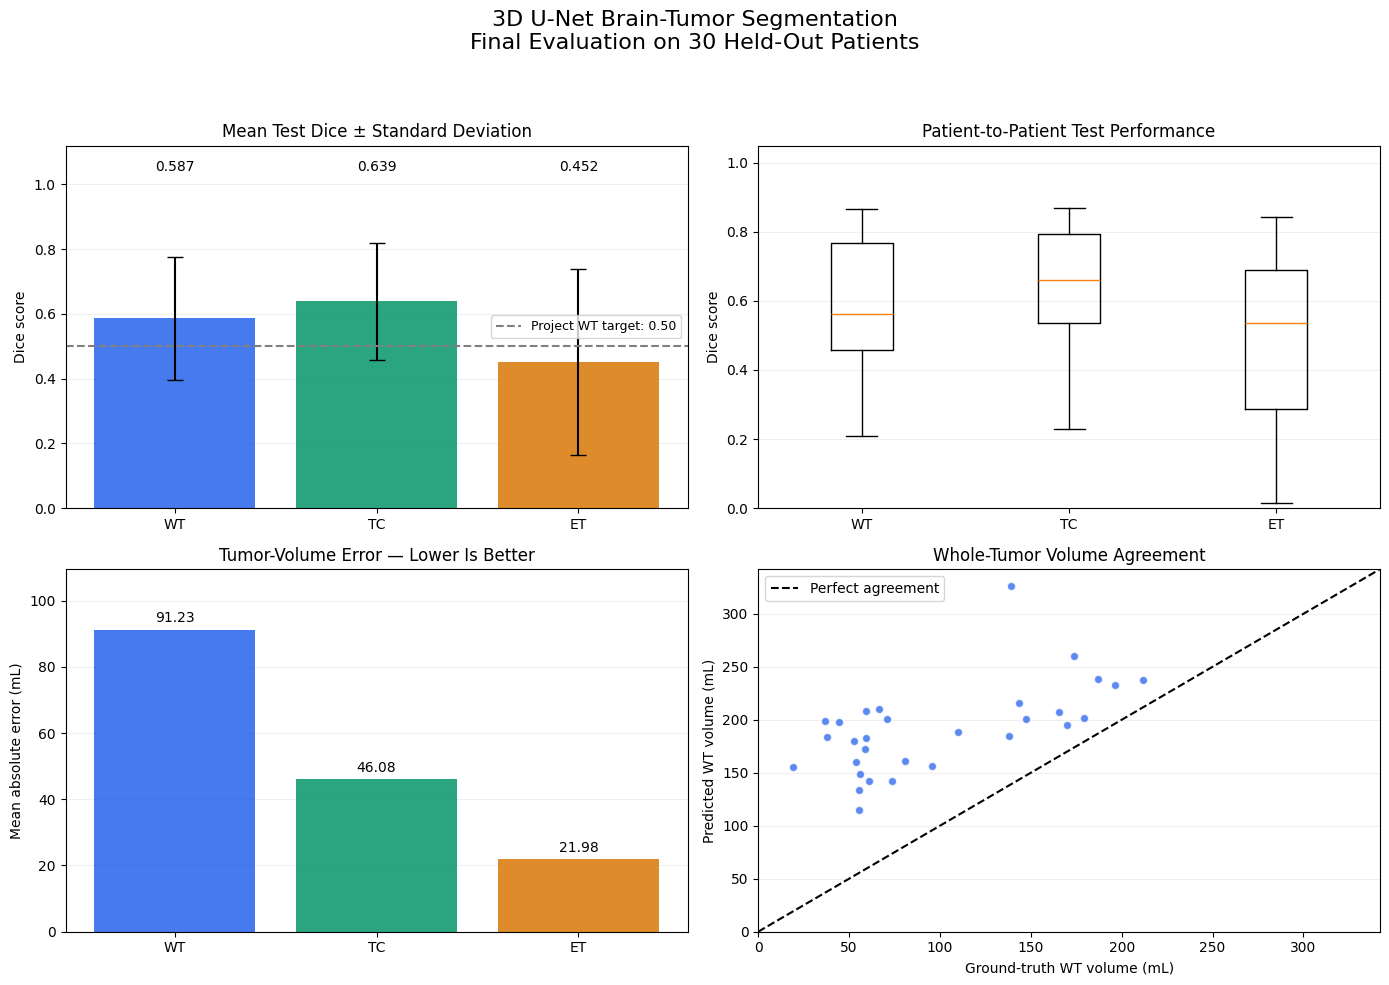

Dashboard saved to Google Drive.


In [31]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
colors = ["#2563EB", "#059669", "#D97706"]
x = np.arange(3)

# A: Mean Dice and patient variation
means = test_summary["mean_dice"].to_numpy()
stds = test_summary["std_dice"].to_numpy()

bars = axes[0, 0].bar(
    x, means,
    yerr=stds,
    capsize=6,
    color=colors,
    alpha=0.85,
)

axes[0, 0].set_xticks(x, region_names)
axes[0, 0].set_ylim(0, 1.12)
axes[0, 0].set_ylabel("Dice score")
axes[0, 0].set_title("Mean Test Dice ± Standard Deviation")
axes[0, 0].axhline(
    0.50, color="gray", linestyle="--",
    label="Project WT target: 0.50",
)

for bar, mean in zip(bars, means):
    axes[0, 0].text(
        bar.get_x() + bar.get_width() / 2,
        1.04,
        f"{mean:.3f}",
        ha="center",
    )

axes[0, 0].legend(fontsize=9)

# B: Distribution of patient Dice scores
dice_groups = [
    test_df.loc[test_df["region"] == region, "dice"].to_numpy()
    for region in region_names
]

axes[0, 1].boxplot(dice_groups)
axes[0, 1].set_xticks([1, 2, 3], region_names)
axes[0, 1].set_ylim(0, 1.05)
axes[0, 1].set_ylabel("Dice score")
axes[0, 1].set_title("Patient-to-Patient Test Performance")

# C: Mean absolute volume error
volume_errors = test_summary["volume_mae_ml"].to_numpy()

volume_bars = axes[1, 0].bar(
    x, volume_errors, color=colors, alpha=0.85
)

axes[1, 0].set_xticks(x, region_names)
axes[1, 0].set_ylabel("Mean absolute error (mL)")
axes[1, 0].set_title("Tumor-Volume Error — Lower Is Better")
axes[1, 0].bar_label(volume_bars, fmt="%.2f", padding=3)
axes[1, 0].margins(y=0.2)

# D: WT volume agreement
wt_results = test_df[test_df["region"] == "WT"]
actual = wt_results["ground_truth_volume_ml"]
predicted = wt_results["predicted_volume_ml"]

axes[1, 1].scatter(
    actual, predicted,
    color=colors[0],
    alpha=0.75,
    edgecolors="white",
)

upper = max(float(actual.max()), float(predicted.max()), 1.0) * 1.05
axes[1, 1].plot(
    [0, upper], [0, upper],
    "k--", label="Perfect agreement",
)

axes[1, 1].set_xlim(0, upper)
axes[1, 1].set_ylim(0, upper)
axes[1, 1].set_xlabel("Ground-truth WT volume (mL)")
axes[1, 1].set_ylabel("Predicted WT volume (mL)")
axes[1, 1].set_title("Whole-Tumor Volume Agreement")
axes[1, 1].legend()

for ax in axes.flat:
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "3D U-Net Brain-Tumor Segmentation\n"
    "Final Evaluation on 30 Held-Out Patients",
    fontsize=16,
)

fig.tight_layout(rect=[0, 0, 1, 0.94])
fig.savefig(
    f"{results_dir}/final_test_dashboard.png",
    dpi=250,
    bbox_inches="tight",
)
plt.show()

print("Dashboard saved to Google Drive.")

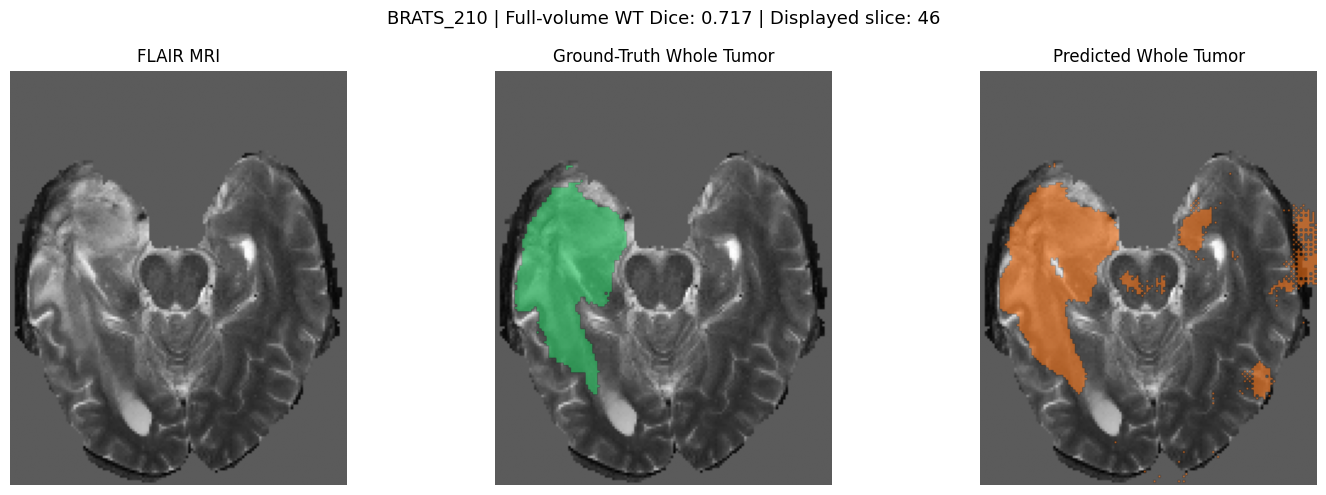

In [32]:
from matplotlib.colors import ListedColormap

assert example_data is not None

flair = example_data["flair"]
gt = example_data["ground_truth_wt"]
pred = example_data["prediction_wt"]

slice_index = int(np.argmax(gt.sum(axis=(0, 1))))

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

for ax in axes:
    ax.imshow(flair[:, :, slice_index].T, cmap="gray", origin="lower")
    ax.axis("off")

axes[0].set_title("FLAIR MRI")

for ax, mask, title, color in [
    (axes[1], gt, "Ground-Truth Whole Tumor", "#22C55E"),
    (axes[2], pred, "Predicted Whole Tumor", "#F97316"),
]:
    mask_slice = mask[:, :, slice_index].T

    ax.imshow(
        np.ma.masked_where(~mask_slice, mask_slice),
        cmap=ListedColormap([color]),
        vmin=0,
        vmax=1,
        alpha=0.6,
        origin="lower",
    )
    ax.set_title(title)

example_wt_dice = test_df.loc[
    (test_df["patient_id"] == example_data["patient_id"])
    & (test_df["region"] == "WT"),
    "dice",
].iloc[0]

fig.suptitle(
    f"{example_data['patient_id']} | "
    f"Full-volume WT Dice: {example_wt_dice:.3f} | "
    f"Displayed slice: {slice_index}",
    fontsize=13,
)

fig.tight_layout()
fig.savefig(
    f"{results_dir}/test_prediction_example.png",
    dpi=250,
    bbox_inches="tight",
)
plt.show()